# 08.8 · CNNs on Fashion-MNIST

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/08-cnns-fashion-mnist/lesson.ipynb)

Read the [README](README.md) first and count the weights of both networks on paper. Then train them here.

Each network trains for 8 epochs on 54,000 photos. That takes seconds on a GPU and about one to three minutes on a laptop CPU. Your accuracies will differ slightly from the printed ones: training on different hardware is not bit-for-bit identical.

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow's C++ start-up messages
warnings.filterwarnings("ignore")                # hide library deprecation notices
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
keras.utils.set_random_seed(42)                  # same start every run (results still vary slightly by machine)
print("Keras", keras.__version__, "· backend", keras.backend.backend())

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
x_train, x_test = x_train / 255.0, x_test / 255.0      # pixels 0-255  ->  0-1
print("train", x_train.shape, " test", x_test.shape)

Keras 3.15.1 · backend tensorflow
train (60000, 28, 28)  test (10000, 28, 28)


photos per class (train): [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


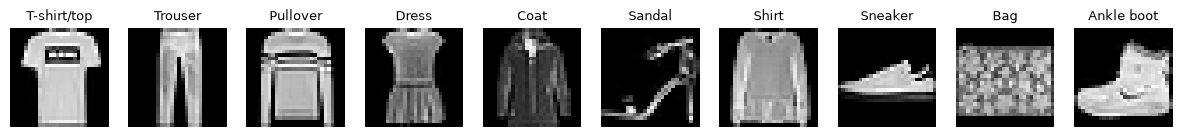

In [2]:
print("photos per class (train):", np.bincount(y_train))
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for label, ax in enumerate(axes):
    ax.imshow(x_train[np.argmax(y_train == label)], cmap="gray")
    ax.set_title(CLASSES[label], fontsize=9); ax.axis("off")
plt.show()

## 1. The baseline

Ten balanced classes: guessing any one class every time is right 10% of the time. Any model must beat that by a lot.

## 2. A dense network

The 08.5 recipe: flatten the 28×28 photo into 784 numbers, one hidden layer of 128, ten outputs.

In [3]:
import time

def dense_model():
    return keras.Sequential([
        keras.Input((28, 28, 1)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ], name="dense")

def cnn_model():
    return keras.Sequential([
        keras.Input((28, 28, 1)),
        layers.Conv2D(16, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ], name="cnn")

def train(model, epochs=8):
    """Compile, fit on the training set (10% held out for validation), return history and seconds."""
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    start = time.time()
    history = model.fit(x_train[..., None], y_train, epochs=epochs, batch_size=128,
                        validation_split=0.1, verbose=0)
    return history, time.time() - start

dense = dense_model()
dense.summary()

Model: "dense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
dense_hist, dense_secs = train(dense)
dense_test = dense.evaluate(x_test[..., None], y_test, verbose=0)[1]
print(f"dense: test accuracy {dense_test:.3f}   ({dense_secs:.0f} s)")

dense: test accuracy 0.873   (3 s)


## 3. A small CNN

Two convolution + pooling blocks find local patterns; a small dense head turns them into a class. Compare the parameter count with your paper.

In [5]:
cnn = cnn_model()
cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
cnn_hist, cnn_secs = train(cnn)
cnn_test = cnn.evaluate(x_test[..., None], y_test, verbose=0)[1]
print(f"cnn:   test accuracy {cnn_test:.3f}   ({cnn_secs:.0f} s)")

cnn:   test accuracy 0.896   (12 s)


In [7]:
import pandas as pd
pd.DataFrame({
    "parameters": [dense.count_params(), cnn.count_params()],
    "train acc":  [dense_hist.history["accuracy"][-1], cnn_hist.history["accuracy"][-1]],
    "val acc":    [dense_hist.history["val_accuracy"][-1], cnn_hist.history["val_accuracy"][-1]],
    "test acc":   [dense_test, cnn_test],
    "seconds":    [dense_secs, cnn_secs],
}, index=["dense", "cnn"]).round(3)

,parameters,train acc,val acc,test acc,seconds
dense,101770,0.898,0.878,0.873,2.688
cnn,56714,0.906,0.900,0.896,12.296


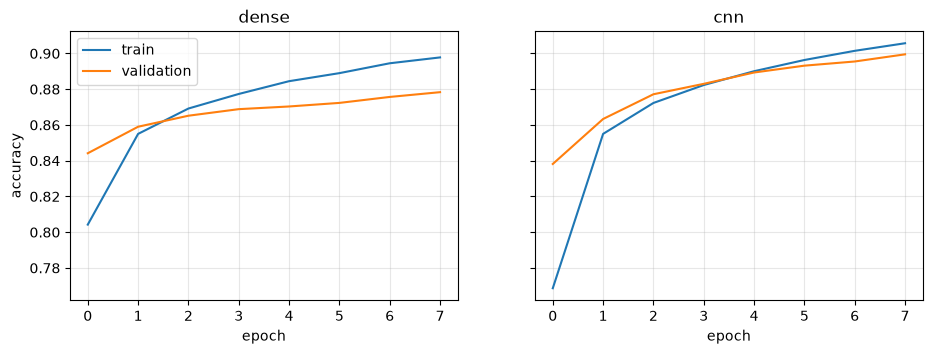

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (name, h) in zip(axes, [("dense", dense_hist), ("cnn", cnn_hist)]):
    ax.plot(h.history["accuracy"], label="train"); ax.plot(h.history["val_accuracy"], label="validation")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.grid(alpha=.3)
axes[0].set_ylabel("accuracy"); axes[0].legend(); plt.show()

The CNN wins with **about half the parameters**, because each filter is reused at every position (08.7). Notice too that the dense network's training accuracy pulls away from its validation accuracy faster: more parameters, more memorising.

## 4. One prediction, opened up

The final softmax layer gives ten probabilities that add up to 1.

In [9]:
i = 0
probs = cnn.predict(x_test[i:i + 1, ..., None], verbose=0)[0]
top = np.argsort(probs)[::-1][:3]
print("true label:", CLASSES[y_test[i]])
for k in top:
    print(f"  {CLASSES[k]:<12} {probs[k]:.3f}")
print("sum of all ten:", round(float(probs.sum()), 3))

true label: Ankle boot
  Ankle boot   0.990
  Sandal       0.005
  Sneaker      0.005
sum of all ten: 1.0


## 5. Where does it go wrong?

Accuracy is one number. The 10×10 confusion matrix shows *which* products get mixed up.

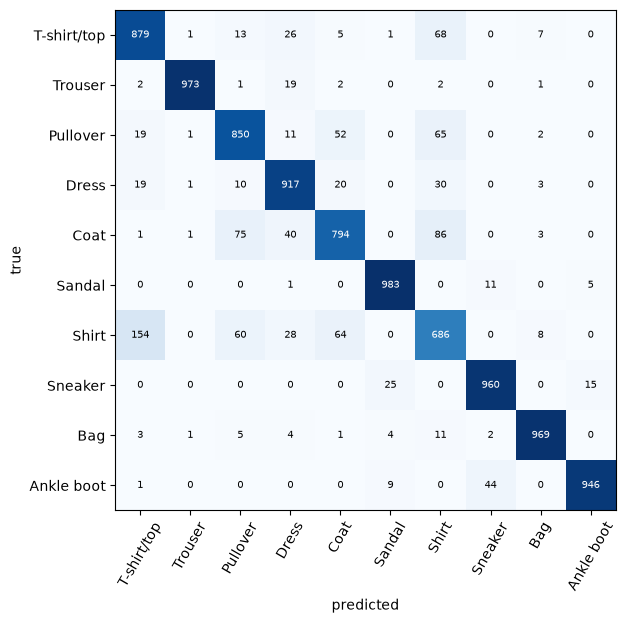

In [10]:
from sklearn.metrics import confusion_matrix
y_pred = cnn.predict(x_test[..., None], verbose=0).argmax(axis=1)
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), CLASSES, rotation=60); ax.set_yticks(range(10), CLASSES)
for (r, c), v in np.ndenumerate(cm):
    ax.text(c, r, v, ha="center", va="center", fontsize=7, color="white" if v > 500 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); plt.show()

In [11]:
pairs = [(cm[r, c], CLASSES[r], CLASSES[c]) for r in range(10) for c in range(10) if r != c]
print("most common mistakes (true → predicted):")
for n, t, p in sorted(pairs, reverse=True)[:5]:
    print(f"  {n:>4}  {t} → {p}")
per_class = cm.diagonal() / cm.sum(axis=1)
print("\nper-class accuracy, worst first:")
for k in np.argsort(per_class)[:4]:
    print(f"  {CLASSES[k]:<12} {per_class[k]:.3f}")

most common mistakes (true → predicted):
   154  Shirt → T-shirt/top
    86  Coat → Shirt
    75  Coat → Pullover
    68  T-shirt/top → Shirt
    65  Pullover → Shirt

per-class accuracy, worst first:
  Shirt        0.686
  Coat         0.794
  Pullover     0.850
  T-shirt/top  0.879


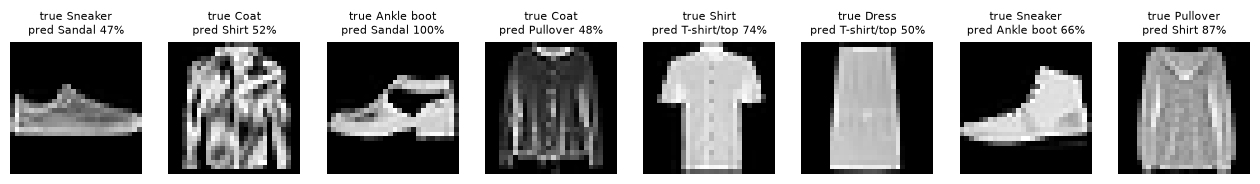

In [12]:
wrong = np.where(y_pred != y_test)[0][:8]
probs_all = cnn.predict(x_test[wrong, ..., None], verbose=0)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i, p in zip(axes, wrong, probs_all):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"true {CLASSES[y_test[i]]}\npred {CLASSES[p.argmax()]} {p.max():.0%}", fontsize=8)
plt.show()

Many mistakes are forgivable: at 28×28 pixels a shirt, a T-shirt, a pullover and a coat really do look alike, and some photos are labelled ambiguously. This is what the ShopWave team should hear before trusting the model: *"Excellent at shoes, bags and trousers; shirts need a human check."*

## 6. What did the network learn?

The first layer has 16 filters of 3×3. They started as random numbers; training shaped them into edge and texture detectors like the hand-made ones in 08.7.

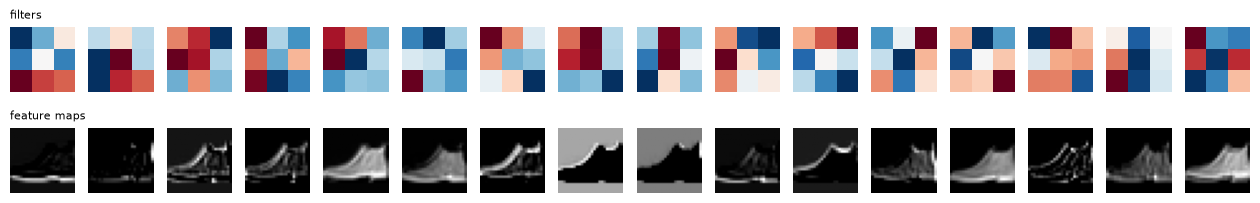

In [13]:
w = cnn.layers[0].get_weights()[0][:, :, 0, :]          # shape (3, 3, 16)
maps = keras.Model(cnn.inputs, cnn.layers[0].output)(x_test[:1, ..., None]).numpy()[0]
fig, axes = plt.subplots(2, 16, figsize=(16, 2.4))
for k in range(16):
    axes[0, k].imshow(w[:, :, k], cmap="RdBu"); axes[0, k].axis("off")
    axes[1, k].imshow(maps[:, :, k], cmap="gray"); axes[1, k].axis("off")
axes[0, 0].set_title("filters", fontsize=8, loc="left"); axes[1, 0].set_title("feature maps", fontsize=8, loc="left")
plt.show()

## Quiz answers

1. 10%: ten balanced classes, so always guessing one class is right one time in ten.
2. 3 × 3 × 16 × 32 + 32 = 4,640.
3. It learns fewer parameters (each filter is reused everywhere) and it uses the fact that neighbouring pixels belong together, so it generalises better.
4. Shirt (and T-shirt/top, pullover, coat): at 28×28 they share the same outline; only small details differ.
5. That validation accuracy is lower than training accuracy and the gap grows with epochs: the model is starting to memorise the training photos (overfitting, 08.6).

**Next:** [08.9 Data augmentation and transfer learning](../09-augmentation-transfer-learning/)